# **Goodreads Book Rating Analysis and Regression**

## **Task background**

In this Portfolio task, I work on a dataset named 'Books' (thanks to Soumik for sharing this dataset on Kaggle). The link to the source is: https://www.kaggle.com/datasets/jealousleopard/goodreadsbooks/data. This coursework project explores 11,127 Goodreads book records. I compared linear and polynomial regression to see how well page count, number of ratings and number of written reviews could predict a book's average rating.

**Description of Fields:**

*   **bookID**: A unique Identification number for each book.
*   **title**: The name under which the book was published.
*   **authors**: Names of the authors of the book. Multiple authors are delimited with -.
*   **average_rating**: The average rating of the book received in total.
*   **isbn**: Another unique number to identify the book, the International Standard Book Number.
*   **isbn13**: A 13-digit ISBN to identify the book, instead of the standard 11-digit ISBN.
*   **language_code**: Helps understand what is the primary language of the book. For instance, eng is standard for English.
*   **num_pages**: Number of pages the book contains.
*   **ratings_count**: Total number of ratings the book received.
*   **text_reviews_count**: Total number of written text reviews the book received.
*   **publication_date**: Date when the book was first published.
*   **publisher**: The name of the publisher.

In [ ]:
# libraries which might be needed
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn.metrics import r2_score

## **Load the dataset and show the basic information (variable identification)**

In [ ]:
data = pd.read_csv('books.csv')

In [ ]:
print("The length of the dataset is", len(data))

The length of the dataset is 11127


In [ ]:
data.shape

(11127, 12)

In [ ]:
data.head()

,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,9/13/2004,Scholastic


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11127 entries, 0 to 11126
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bookID              11127 non-null  int64  
 1   title               11127 non-null  object 
 2   authors             11127 non-null  object 
 3   average_rating      11127 non-null  float64
 4   isbn                11127 non-null  object 
 5   isbn13              11127 non-null  int64  
 6   language_code       11127 non-null  object 
 7     num_pages         11127 non-null  int64  
 8   ratings_count       11127 non-null  int64  
 9   text_reviews_count  11127 non-null  int64  
 10  publication_date    11127 non-null  object 
 11  publisher           11127 non-null  object 
dtypes: float64(1), int64(5), object(6)
memory usage: 1.0+ MB


In [ ]:
data.describe(include="all")

,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
count,11127.000000,11127,11127,11127.000000,11127,1.112700e+04,11127,11127.000000,1.112700e+04,11127.000000,11127,11127
unique,NaN,10352,6643,NaN,11127,NaN,27,NaN,NaN,NaN,3679,2292
top,NaN,The Brothers Karamazov,Stephen King,NaN,0439785960,NaN,eng,NaN,NaN,NaN,10/1/2005,Vintage
freq,NaN,9,40,NaN,1,NaN,8911,NaN,NaN,NaN,56,318
mean,21310.938887,NaN,NaN,3.933631,NaN,9.759888e+12,NaN,336.376921,1.793641e+04,541.854498,NaN,NaN
std,13093.358023,NaN,NaN,0.352445,NaN,4.428964e+11,NaN,241.127305,1.124794e+05,2576.176608,NaN,NaN
min,1.000000,NaN,NaN,0.000000,NaN,8.987060e+09,NaN,0.000000,0.000000e+00,0.000000,NaN,NaN
25%,10287.000000,NaN,NaN,3.770000,NaN,9.780345e+12,NaN,192.000000,1.040000e+02,9.000000,NaN,NaN
50%,20287.000000,NaN,NaN,3.960000,NaN,9.780586e+12,NaN,299.000000,7.450000e+02,46.000000,NaN,NaN
75%,32104.500000,NaN,NaN,4.135000,NaN,9.780873e+12,NaN,416.000000,4.993500e+03,237.500000,NaN,NaN


## **Clean the dataset**

### **1. Handle the missing value (missing value treatment)**

In [ ]:
# presenting the number of null value for each column
data.isnull().sum()

,0
bookID,0
title,0
authors,0
average_rating,0
isbn,0
isbn13,0
language_code,0
num_pages,0
ratings_count,0
text_reviews_count,0


There are no missing values, so no columns need to be edited.

### **2. Handle the categorical attributes**
If the all the categorical values of the column are unique, the column does not provide any statistical information and should be deleted.

In [ ]:
data.nunique()

,0
bookID,11127
title,10352
authors,6643
average_rating,209
isbn,11127
isbn13,11127
language_code,27
num_pages,997
ratings_count,5294
text_reviews_count,1822


In [ ]:
# drop the column bookID because the values within are unique
cleaned_data = data.drop(columns = ['bookID'])

In [ ]:
# drop the column insb because the values within are unique
cleaned_data = cleaned_data.drop(columns = ['isbn'])

In [ ]:
# drop the column insb13 because the values within are unique
cleaned_data =cleaned_data.drop(columns = ['isbn13'])

In [ ]:
# the shape of the cleaned dataset
cleaned_data.shape

(11127, 9)

In [ ]:
# display the cleaned dataset
cleaned_data.head()

,title,authors,average_rating,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,eng,352,6333,244,11/1/2003,Scholastic
3,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,eng,2690,41428,164,9/13/2004,Scholastic


## **Plotting and Analysis**

### **Question 1:** (univariate analysis) Distribution of Average Ratings

1.1,   What is the typical range of average book ratings, and how are ratings distributed across books?

2.2,   Why do some books have very low ratings, and are they outliers?

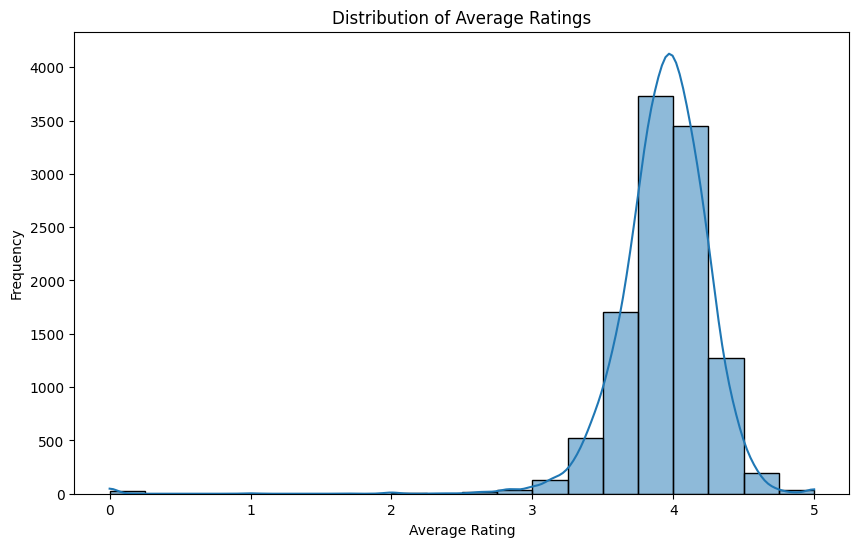

In [ ]:
# plotting the distribution of 'average_rating'
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.histplot(cleaned_data['average_rating'], kde=True, bins=20)
plt.title('Distribution of Average Ratings')
plt.xlabel('Average Rating')
plt.ylabel('Frequency')
plt.show()

**Question 1.1:**

**Observation:** From the plot, we can see that the majority of the ratings are concentrated between 3.0 and 4.5. There is a clear peak around 4.0, which suggests that most books receive ratings around this value.

**Analysis:**
*   The distribution is left-skewed, with very few books having low ratings below 3.0.
*   A large number of books cluster between 3.5 and 4.5, suggesting that readers generally rate books positively.
*   A smaller proportion of books fall in the higher and lower extremes, with very few books having average ratings below 2 or above 4.7.

**Question 1.2:**

**Observation:** From the plot, there is a small but noticeable presence of books with average ratings below 2.0. These low ratings are outliers, as they deviate significantly from the main distribution.

**Explaination:**
*   Books with very low ratings could have issues like poor writing quality, unappealing content, or they may simply have targeted the wrong audience.
*   Negative reviews could be driven by reader expectations not being met, controversies surrounding the book, or problematic subject matter.













### **Question 2:** (univariate analysis) What are the most frequently published languages in the dataset?


Determine the most common languages represented.

Assess the diversity of the collection.



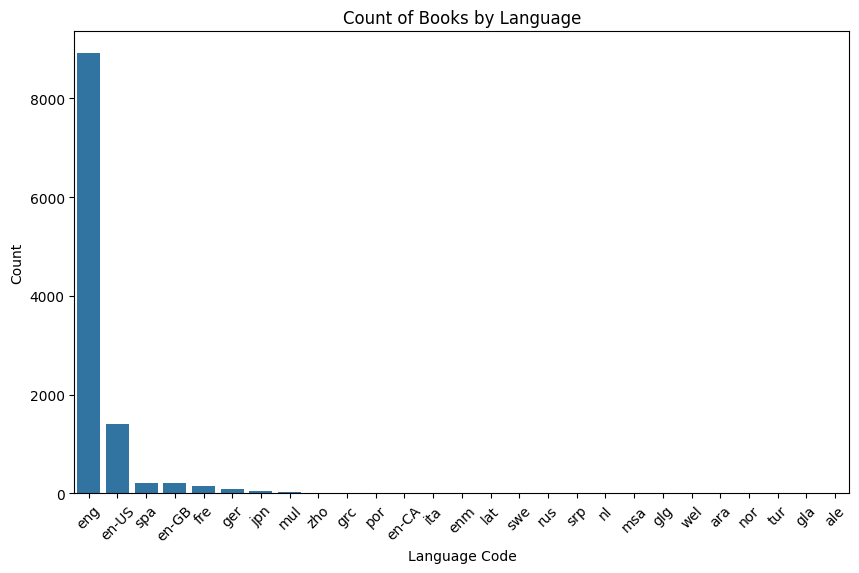

In [ ]:
# plotting the count of books by language
plt.figure(figsize=(10, 6))
sns.countplot(data=cleaned_data, x='language_code', order=cleaned_data['language_code'].value_counts().index)
plt.title('Count of Books by Language')
plt.xlabel('Language Code')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

*   **Top Languages:** From the chart, it is clear that the English language ("eng") dominates, with the second and third most common being "en-US" and "spa" (Spanish). This suggests that English is by far the most frequent language in the dataset.
*   **Diversity Assessment:** The graph shows a long tail, indicating that a variety of other languages are represented, though in much smaller quantities. The diversity of the collection seems to be low in terms of balance, as the vast majority of books are in English, with only small numbers in other languages.



### **Question 3:** (bivariate analysis) The Correlation between Ratings Count and Average Rating

3.1, Explore the correlation between ratings_count and average_rating using plot. Summarise what the plot shows (observation and explanation).

3.2, Get the correlation between ratings_count and average_rating by using the `corr()` method. Provide necessary analysis on the correlation.





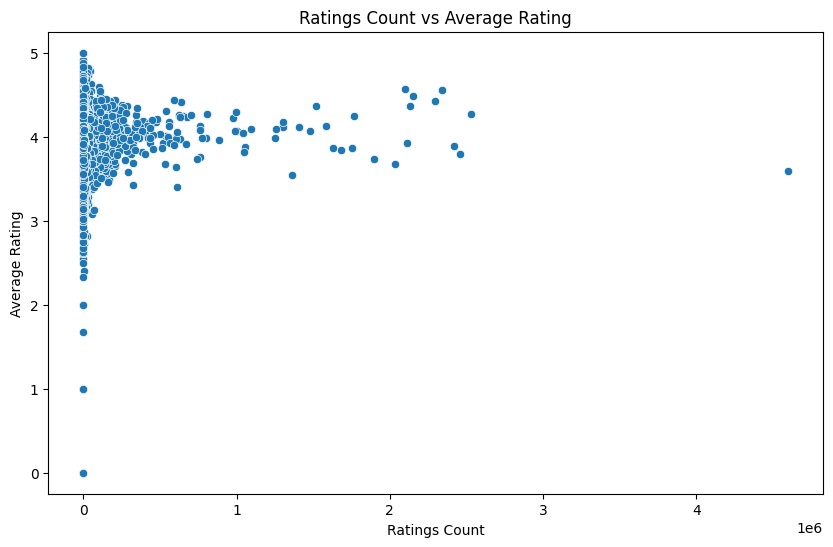

In [ ]:
# 3.1, scatter plot of 'ratings_count' vs 'average_rating'
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cleaned_data, x='ratings_count', y='average_rating')
plt.title('Ratings Count vs Average Rating')
plt.xlabel('Ratings Count')
plt.ylabel('Average Rating')
plt.show()

In [ ]:
# 3.2,
# encoding part
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder(dtype=int)

cleaned_data['ratings_count_encoded'] = encoder.fit_transform(cleaned_data[['ratings_count']])

# correlation calculation part
corr_average_rating = cleaned_data['average_rating'].corr(cleaned_data['ratings_count_encoded'])
print("The correlation between ratings count and average rating is:", corr_average_rating)


The correlation between ratings count and average rating is: 0.09700248833749078


**Question 3.1:**

**Observation:**
*   The plot shows a dense cluster of books that have very low ratings counts (near 0), but their average ratings range from 2 to 5. This indicates that many books in the dataset have received few ratings, and the quality of these books (as perceived by their readers) varies widely.
*   As the number of ratings increases, we see fewer books in this range, but their average ratings tend to cluster around the 3.5 to 4.5 range. This indicates that books with more ratings generally have a higher and more consistent average rating, with fewer books receiving very low ratings in this group.
*   A few books with very high ratings counts (up to 4 million) exist, and they tend to maintain a relatively high average rating (around 4). Additionally, there are some outliers near the bottom of the chart with low average ratings but few ratings, indicating that some books are not well-received despite being rated by a small number of readers.
*   Visually, **there is no clear, strong trend between ratings count and average rating**. The points are fairly dispersed, especially for books with fewer ratings.

**Explaination:**
*   Books with higher ratings counts tend to stabilize around an average rating between 4 and 5. This may be because popular books are generally well-regarded or have a large enough sample of reviews that averages out extreme opinions.
*   For books with fewer ratings, the average rating varies significantly, likely because even a few extreme ratings can skew the average.
*   Some books with a high number of ratings have slightly lower average ratings (around 3 to 4), indicating that popularity doesn't always mean universal praise.


**Question 3.2:**

**Analysis on the correlation:** The correlation between ratings count and average rating is 0.097, which indicates a **very weak positive relationship**. This suggests that as the number of ratings increases, there is a slight tendency for the average rating to increase, but the relationship is not strong. In other words, while books with more ratings may have slightly higher average ratings, the effect is minimal, and there is no substantial linear connection between these two variables.





### **Question 4:** (Linear Regression) Can we predict a book's average rating based on its metadata?

Using features like `num_pages`, `ratings_count`, and `text_reviews_count` to build a predictive model for `average_rating`

Mean Squared Error (MSE): 0.11779231363441191
R-squared: 0.026169692807879286


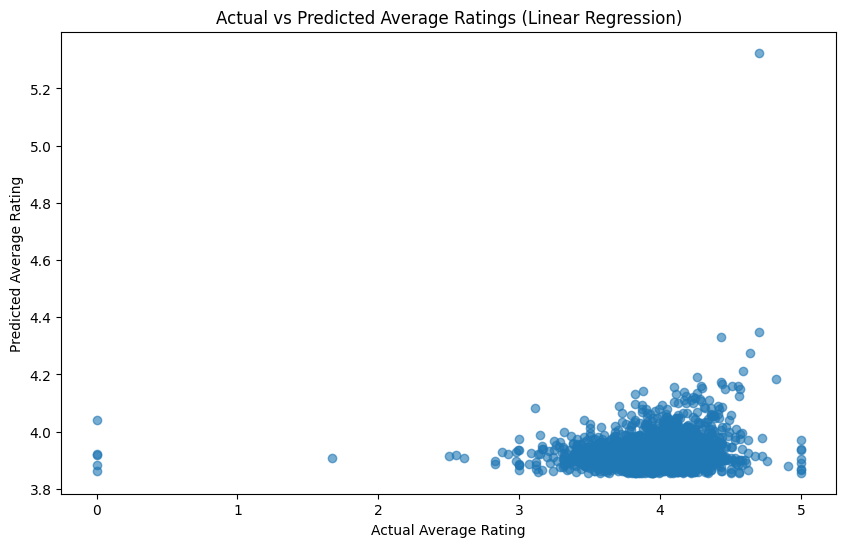

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# selecting relevant features for prediction
features = ['  num_pages', 'ratings_count', 'text_reviews_count']
X = cleaned_data[features]
y = cleaned_data['average_rating']

# splitting the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# initialize the linear regression model
model = LinearRegression()

# fit the model
model.fit(X_train, y_train)

# predict using the test set
y_pred = model.predict(X_test)

# model evaluation
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("R-squared:", r2_score(y_test, y_pred))

# visualize predicted vs actual average ratings
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.title('Actual vs Predicted Average Ratings (Linear Regression)')
plt.xlabel('Actual Average Rating')
plt.ylabel('Predicted Average Rating')
plt.show()


**Observation:**
*   The MSE value of 0.118 is relatively high, indicating that the model's predictions deviate significantly from the actual ratings. This suggests **the linear regression model is not capturing the relationship between the features and the average rating effectively**.
*   The R-squared value of 0.026 is very low, meaning the model explains only about 2.6% of the variance in the average ratings. This strongly indicates that **the linear regression model is underperforming and not suitable for this dataset in its current form.**

**Analysis:**
*   The plot shows that the predicted ratings cluster tightly around a narrow range (3.8 to 4.2), while actual ratings are spread over a wider range (0 to 5)
*   There is significant dispersion between the actual and predicted values, especially for lower actual ratings, where the predictions are far from accurate.
*   This shows that the model tends to predict ratings in a very narrow band and struggles to capture the full variation in the actual ratings.




### **Question 5:** (Polynomial Regression) How can we improve this model?
Using Polynomial Regression: This will allow the model to capture non-linear relationships between the features and target variable (ratings).

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)  # X represents the features
model.fit(X_poly, y)


LinearRegression()

Polynomial Regression Mean Squared Error (MSE): 0.11799253788592819
Polynomial Regression R-squared: 0.024514368802897146


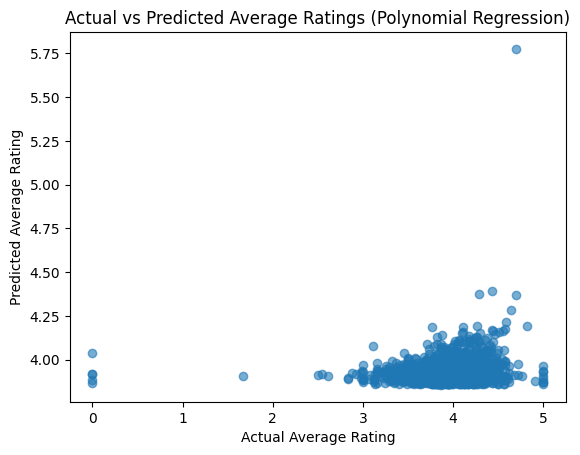

In [ ]:
# import necessary libraries
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# prepare the data
features = ['  num_pages', 'ratings_count', 'text_reviews_count']
X = cleaned_data[features]
y = cleaned_data['average_rating'].fillna(cleaned_data['average_rating'].median())

# split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# apply polynomial features transformation (degree=2)
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# fit a linear regression model on the transformed data
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# predict using the test set
y_pred_poly = poly_model.predict(X_test_poly)

# model evaluation for polynomial regression
print("Polynomial Regression Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred_poly))
print("Polynomial Regression R-squared:", r2_score(y_test, y_pred_poly))

# visualize the actual vs predicted ratings for polynomial regression
plt.scatter(y_test, y_pred_poly, alpha=0.6)
plt.title('Actual vs Predicted Average Ratings (Polynomial Regression)')
plt.xlabel('Actual Average Rating')
plt.ylabel('Predicted Average Rating')
plt.show()


**Comparison:**

**Simple Linear Regression:**

MSE: 0.11779231363441191

R-squared: 0.026169692807879286

**Polynomial Regression (Degree 2):**

MSE: 0.11799253788592819

R-squared: 0.024514368802897146

**Analysis:**
*   The MSE for both models is nearly identical. The simple linear regression model shows a slightly lower error (0.11779) compared to the degree 2 polynomial regression (0.11799). The difference in MSE is minimal, indicating that adding polynomial terms does not significantly improve the model's prediction accuracy.
*   The R-squared value for the polynomial regression (0.0245) is slightly lower than the simple linear regression (0.0262). This means the polynomial model (degree 2) explains slightly less variance in the target variable compared to the simple linear regression model. The difference is small, but it suggests that the polynomial terms doesn't provide a better fit.

**Explanation:** The polynomial regression did not improve the model significantly. This may be because the dataset's features (for example, num_pages, ratings_count) don't have complex non-linear relationships with the target variable (average_rating). The dataset which I have chosen might not be well-suited for polynomial regression.
